# Van de Vusse — physics-informed ReLU-RNN surrogate, pruned and embedded in an MPC MILP

This notebook exercises the recurrent engine (`pwlnet.recurrent`) end-to-end on the
isothermal Van de Vusse CSTR

```text
A -> B -> C,    2A -> D            control: dilution rate D = F/V  [1/min]
```

The goal is a **small** dynamic surrogate that the optimiser can embed *exactly*. A
vanilla Elman cell with a `relu` activation is piecewise-linear, so it carries no
LSTM/GRU/tanh/sigmoid — it is MILP-exact via the existing `relu_bigm` formulation.

Workflow:

1. Build a **sequence** dataset: control profiles `D[t]` → state trajectories `(CA,CB,CC,CD)[t]`.
2. Train a **physics-informed** ReLU-RNN: data loss **+ a high-weight bound penalty**
   (predicted concentrations must stay within physical limits) **+ a process-model
   residual** (the predicted trajectory must obey the known Van de Vusse ODE). The
   physics pressure is what lets a *small* net learn the process rather than memorise.
3. **Prune before working** — exact dead-unit removal, then importance-based shrinking.
4. Show **learning quality before vs after pruning**, and **plot the losses**.
5. **Bound-tighten** across the horizon and **unroll** the cell into a receding-horizon
   MILP that drives `CB` to its product optimum; verify the embedding is exact.

## Setup

In [14]:
from __future__ import annotations

import logging
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt

ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "pyproject.toml").exists() and (candidate / "src" / "pwlnet").exists():
        ROOT = candidate
        break
if ROOT is None:
    raise RuntimeError("Could not find the PWLNet project root from the notebook directory.")
src = ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

# OMLT initialises its internal block variables to 0, which Pyomo flags (W1002)
# against the tight, h0-seeded input bounds. The solve is unaffected, so silence it.
logging.getLogger("pyomo.core").setLevel(logging.ERROR)

from pwlnet.training.rnn_trainer import RNNTrainer
from pwlnet.processes.van_de_vusse import (
    DECISION_DT_MIN,
    STATE_BOUNDS,
    STATE_NAMES,
    VanDeVusseParameters,
    find_max_product_dilution,
    random_control_profiles,
    simulate_policy,
    steady_state,
)

plt.style.use("seaborn-v0_8-whitegrid")
PARAMS = VanDeVusseParameters()
DT = DECISION_DT_MIN          # 0.10 min decision step
T = 40                        # steps per training trajectory (4 min)
CB = STATE_NAMES.index("CB")  # index of the product concentration
RANDOM_SEED = 0
print("states:", STATE_NAMES, "| control: D | dt =", DT, "min")

states: ['CA', 'CB', 'CC', 'CD'] | control: D | dt = 0.1 min


## 1. Sequence dataset

For the RNN the exogenous input is the control sequence `D[t]`; the targets are the
state trajectories. Each trajectory starts at the steady state of `D[0]`, so the
control sequence determines the response (a stable CSTR forgets its initial condition).
The hidden state of the RNN plays the role of the latent reactor state.

In [15]:
def make_sequences(n_traj: int, seed: int):
    # Return (U, Y): controls (n, T, 1) and states (n, T, 4), original units.
    rng = np.random.default_rng(seed)
    U, Y = [], []
    for _ in range(n_traj):
        profile = random_control_profiles(rng, n_steps=T, params=PARAMS)
        x0 = steady_state(float(profile[0]), params=PARAMS)
        _, states = simulate_policy(profile, params=PARAMS, x0=x0, dt_min=DT, n_substeps=2)
        U.append(profile[:, None])   # D[t]
        Y.append(states[1:])         # state AFTER applying D[t]
    return np.asarray(U), np.asarray(Y)

U_train, Y_train = make_sequences(120, seed=1)
U_val, Y_val = make_sequences(30, seed=2)
print("U_train", U_train.shape, "Y_train", Y_train.shape)

U_train (120, 40, 1) Y_train (120, 40, 4)


## 2. Physics: a high bound penalty + the process-model residual

Two physics terms ride alongside the data loss (both evaluated in **original units**
inside the training graph):

* **Bound penalty (kept high).** Concentrations are physical: `CA∈[0,10]`, `CB∈[0,2]`,
  etc. The penalty `mean(relu(y-ub)^2 + relu(lb-y)^2)` pushes every prediction back
  into `STATE_BOUNDS`. A large weight makes these effectively hard limits.
* **Process-model residual.** The predicted trajectory must satisfy the known Van de
  Vusse ODE in discretised form, `(y[t]-y[t-1])/dt ≈ rhs(y[t-1], D[t])`. This injects
  real process understanding, so a small network learns dynamics instead of curve-fitting.

In [16]:
def vdv_residual(tf, u_orig, y_orig):
    # Discretised Van de Vusse ODE residual on the predicted sequence.
    #   u_orig: (batch, T, 1) = D;  y_orig: (batch, T, 4) = predicted (CA,CB,CC,CD).
    # Returns (batch, T-1, 4); the trainer penalises its mean square.
    p = PARAMS
    CA, CBc, CC, CD = (y_orig[..., i] for i in range(4))
    d = u_orig[..., 0]
    rhs = tf.stack(
        [
            d * (p.caf - CA) - p.k1 * CA - p.k3 * CA * CA,
            p.k1 * CA - (d + p.k2) * CBc,
            p.k2 * CBc - d * CC,
            0.5 * p.k3 * CA * CA - d * CD,
        ],
        axis=-1,
    )
    # control D[t] drives the transition y[t-1] -> y[t]
    return (y_orig[:, 1:, :] - y_orig[:, :-1, :]) / DT - rhs[:, 1:, :]

## 3. Train a good-enough physics-informed ReLU-RNN

We deliberately start a touch over-sized (32 hidden units) so pruning has slack to
remove later. `bound_penalty_weight` is high; the physics residual is weighted modestly.
When a physics term is active the trainer switches to a custom `tf.GradientTape` loop
and records each loss term separately in `history_`.

In [17]:
import json

from pwlnet.recurrent import RecurrentCell

DATASETS = ROOT / "datasets"
CELL_CACHE = DATASETS / "12_vdv_relu_rnn_cell_32u.json"
HIST_CACHE = DATASETS / "12_vdv_relu_rnn_history_32u.json"
RETRAIN = False   # set True (or delete the cache files) to force retraining

if CELL_CACHE.exists() and HIST_CACHE.exists() and not RETRAIN:
    cell = RecurrentCell.load(CELL_CACHE)
    history = json.loads(HIST_CACHE.read_text())
    print(f"loaded cached cell from {CELL_CACHE.relative_to(ROOT)} "
          "(set RETRAIN=True to retrain)")
    print(cell)
else:
    trainer = RNNTrainer(
        hidden_units=32,
        epochs=150,
        learning_rate=1e-3,
        random_seed=RANDOM_SEED,
        early_stopping_patience=40,
        output_bounds=[tuple(b) for b in STATE_BOUNDS],
        bound_penalty_weight=80.0,      # <-- keep the bound penalty HIGH
        physics_residual=vdv_residual,
        physics_weight=0.5,
        verbose=0,
    )
    cell = trainer.fit(U_train, Y_train, validation_data=(U_val, Y_val))
    history = {k: [float(x) for x in v] for k, v in trainer.history_.items()}
    DATASETS.mkdir(exist_ok=True)
    cell.save(CELL_CACHE)
    HIST_CACHE.write_text(json.dumps(history))
    print(cell)
    print("cell <-> Keras rollout agreement:", f"{trainer.equivalence_error_:.2e}")
print("loss terms tracked:", sorted(history))

loaded cached cell from datasets\12_vdv_relu_rnn_cell_32u.json (set RETRAIN=True to retrain)
RecurrentCell(n_exog=1, n_hidden=32, n_outputs=4, readout=yes)
loss terms tracked: ['bound_loss', 'data_loss', 'epoch', 'loss', 'physics_loss', 'val_bound_loss', 'val_data_loss', 'val_loss', 'val_physics_loss']


## 4. Plot the losses

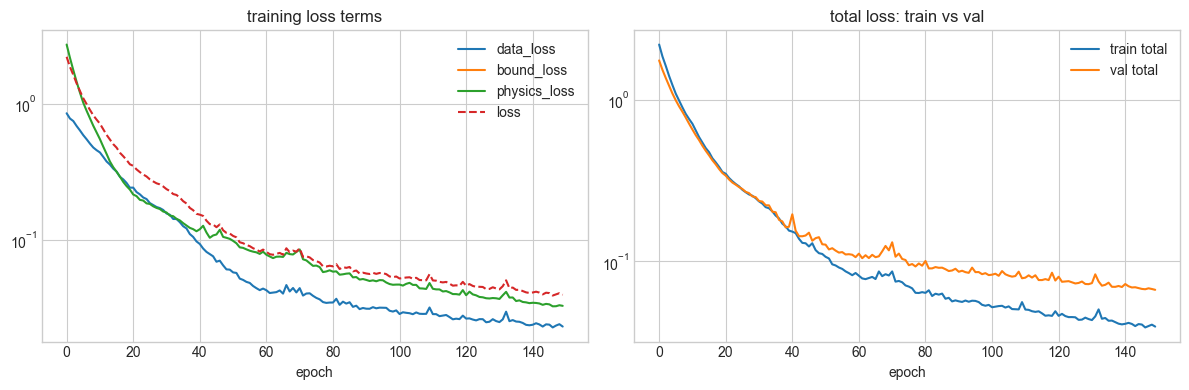

In [18]:
h = history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key in ["data_loss", "bound_loss", "physics_loss", "loss"]:
    ax[0].plot(h[key], label=key, ls="--" if key == "loss" else "-")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_title("training loss terms")
ax[0].legend()
ax[1].plot(h["loss"], label="train total")
ax[1].plot(h["val_loss"], label="val total")
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_title("total loss: train vs val")
ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Learning quality *before* pruning

We score the surrogate by rolling it open-loop over the validation control sequences
(latent state starts at zero) and comparing to the true plant — the regime the embedded
MPC will actually use.

In [19]:
def rollout_mae(c, U, Y):
    # Per-output MAE of an open-loop rollout against the true plant.
    errs = [np.abs(c.rollout(np.zeros(c.n_hidden), u)[1] - yt) for u, yt in zip(U, Y)]
    return np.concatenate(errs, axis=0).mean(axis=0)

mae_before = rollout_mae(cell, U_val, Y_val)
print("validation MAE per output (32 units):",
      {n: round(float(v), 4) for n, v in zip(STATE_NAMES, mae_before)})

validation MAE per output (32 units): {'CA': 0.0648, 'CB': 0.0194, 'CC': 0.1012, 'CD': 0.0289}


## 6. Prune *before* working

Two steps, both reusing the engine:

1. **Exact dead-unit removal** (`prune_dead_units`) — drops any hidden unit provably
   pinned to `relu(z)=0` over the operating box. Sound but conservative: a well-trained
   net often has none, which is fine.
2. **Importance-based shrinking** (`prune_least_important`) — lossy: trims the units
   that move least and feed the readout least, down to a compact width. This is what
   makes the embedded MILP small (fewer big-M binaries).

In [20]:
dead_cell, dead = cell.prune_dead_units()
small, removed = dead_cell.prune_least_important(U_train, n_keep=12)
print(f"dead units removed (exact): {len(dead)}")
print(f"importance units removed:   {len(removed)}  ->  hidden {cell.n_hidden} to {small.n_hidden}")

mae_after = rollout_mae(small, U_val, Y_val)
print("validation MAE per output (12 units):",
      {n: round(float(v), 4) for n, v in zip(STATE_NAMES, mae_after)})
print(f"CB MAE: {mae_before[CB]:.4f} (32u)  ->  {mae_after[CB]:.4f} (12u)")

dead units removed (exact): 0
importance units removed:   20  ->  hidden 32 to 12
validation MAE per output (12 units): {'CA': 0.3022, 'CB': 0.0564, 'CC': 0.4, 'CD': 0.0721}
CB MAE: 0.0194 (32u)  ->  0.0564 (12u)


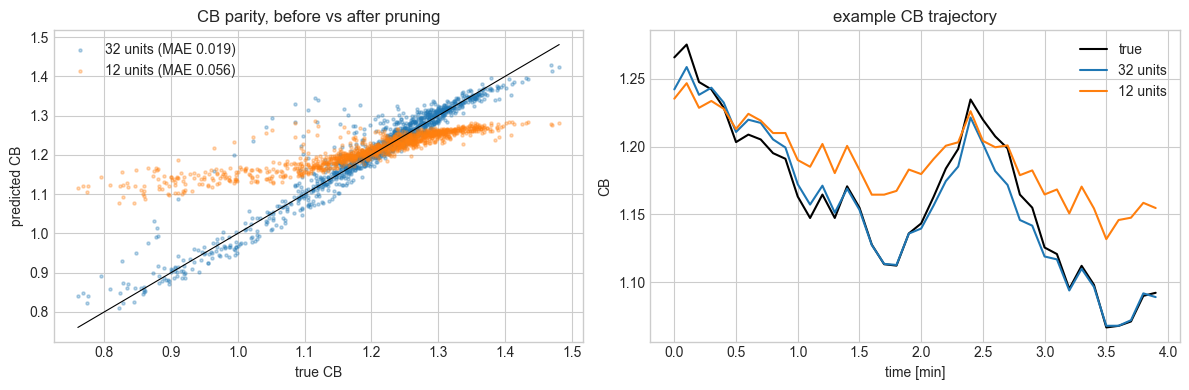

In [21]:
# Before/after parity on CB (the controlled output).
pred_b = np.concatenate([cell.rollout(np.zeros(cell.n_hidden), u)[1][:, CB] for u in U_val])
pred_a = np.concatenate([small.rollout(np.zeros(small.n_hidden), u)[1][:, CB] for u in U_val])
true_cb = np.concatenate([yt[:, CB] for yt in Y_val])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(true_cb, pred_b, s=5, alpha=0.3, label=f"32 units (MAE {mae_before[CB]:.3f})")
ax[0].scatter(true_cb, pred_a, s=5, alpha=0.3, label=f"12 units (MAE {mae_after[CB]:.3f})")
lim = [true_cb.min(), true_cb.max()]; ax[0].plot(lim, lim, "k-", lw=0.8)
ax[0].set_xlabel("true CB"); ax[0].set_ylabel("predicted CB")
ax[0].set_title("CB parity, before vs after pruning"); ax[0].legend()

t_axis = np.arange(T) * DT
_, y32 = cell.rollout(np.zeros(cell.n_hidden), U_val[0])
_, y12 = small.rollout(np.zeros(small.n_hidden), U_val[0])
ax[1].plot(t_axis, Y_val[0][:, CB], "k", label="true")
ax[1].plot(t_axis, y32[:, CB], label="32 units")
ax[1].plot(t_axis, y12[:, CB], label="12 units")
ax[1].set_xlabel("time [min]"); ax[1].set_ylabel("CB"); ax[1].set_title("example CB trajectory")
ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Bound-tighten across the horizon

Before unrolling, interval bounds are propagated step by step (`recurrent_bounds`):
the hidden box at step `t+1` is the image of step `t`'s box through the cell. Each
step's box feeds that step's `relu_bigm` big-M constants. Note the box **grows** with
the horizon when the recurrence has spectral radius > 1 — the bounds stay *valid* but
loosen, so a short horizon keeps the MILP tight. (When the model is actually built, the
propagation is re-seeded from the exact warm-started `h0`, giving tighter per-solve boxes.)

In [22]:
H = 4  # MPC horizon (short -> tight big-M, fast solve)
rb = small.recurrent_bounds(H)
print("max |hidden| upper bound per node:",
      [round(float(np.max(np.abs(hi))), 2) for _, hi in rb.hidden_bounds])

max |hidden| upper bound per node: [6.91, 8.43, 12.21, 18.25, 26.52]


## 8. Unroll into a MILP and solve one MPC move

We drive `CB` to its steady-state product optimum `CB*`. The latent initial state is
**warm-started** by replaying a short control history through the cell (it is not
measurable). The model chains one `relu_bigm` block per step, carries the hidden state,
and adds the linear readout + an L1 tracking/move objective — a pure MILP.

In [23]:
cb_star = find_max_product_dilution(params=PARAMS).cb
h0 = small.encode(np.full((6, 1), 0.8))   # warm-start latent state from recent D-history

result = small.solve_mpc(
    h0, H,
    setpoint=[0.0, cb_star, 0.0, 0.0],
    output_weights=[0.0, 1.0, 0.0, 0.0],   # track CB only
    move_penalty=0.02, u_prev=[0.8],
    mip_gap=0.01, solver_options={"time_limit": 30.0},
)
print(f"status={result['status']}/{result['termination']}  "
      f"binaries={result['n_binaries']}  solve={result['solve_seconds']:.2f}s")
print(f"first control D = {float(result['u0'][0]):.3f}  (CB* target = {cb_star:.3f})")

# The embedding is exact: re-roll the chosen plan through the numpy cell.
_, y_check = small.rollout(h0, result["u"])
print("MILP vs numpy rollout max error:", f"{np.max(np.abs(result['y'] - y_check)):.1e}")

status=ok/optimal  binaries=48  solve=0.92s
first control D = 0.434  (CB* target = 1.266)
MILP vs numpy rollout max error: 4.4e-16


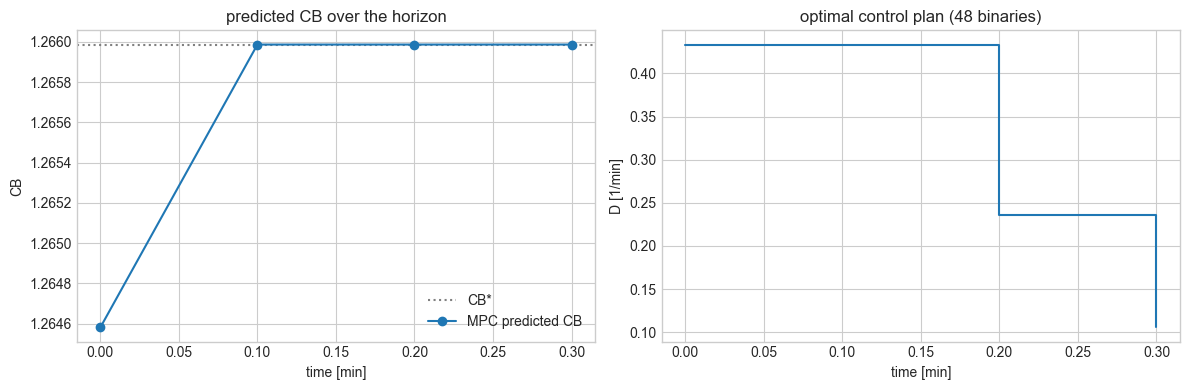

In [24]:
t_axis = np.arange(H) * DT
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].axhline(cb_star, ls=":", c="grey", label="CB*")
ax[0].plot(t_axis, result["y"][:, CB], "o-", label="MPC predicted CB")
ax[0].set_xlabel("time [min]"); ax[0].set_ylabel("CB"); ax[0].set_title("predicted CB over the horizon")
ax[0].legend()
ax[1].step(t_axis, result["u"][:, 0], where="post")
ax[1].set_xlabel("time [min]"); ax[1].set_ylabel("D [1/min]")
ax[1].set_title(f"optimal control plan ({result['n_binaries']} binaries)")
plt.tight_layout(); plt.show()

## 9. Economic objective — maximize the economic payoff over the horizon

Section 8 tracks a fixed setpoint. Here we instead solve a genuine **economic optimal
control** problem over a horizon five times as long (`H = 20` steps, 2 min): find the
dilution profile `D[0..H-1]` that maximizes a **running economic payoff**

```text
J = dt * sum_t [ p_B*CB_t - c_C*CC_t - c_D*CD_t - c_F*D_t ]  -  w * sum_t |dD_t|
```

i.e. revenue for the product `B` minus disposal costs for the byproducts `C` and `D`
and a feed/pumping cost proportional to the throughput `D`. On top of that the
actuator carries a **ramp-rate limit** `|dD_t| <= 0.25` per move, so the optimizer
cannot simply jump to the best operating point — it has to *plan a ramp*.

A 20-step chain of `relu_bigm` blocks is a genuinely hard MILP: the propagated hidden
boxes (Section 7) grow geometrically, so the late-step big-M constants balloon and the
LP relaxation goes weak — an untuned solve can run for hours. Three standard measures
make it tractable (all still exact):

1. **Ramp-aware bound propagation.** The reachable dilution at step `t` is only
   `u_prev ± 0.25·(moves so far)`, so we thread `propagate_recurrent_bounds` one step
   at a time with the per-step reachable `D` interval instead of the full `[0.1, 4]`
   box. This cuts the late hidden boxes by ~2.5x.
2. **Move blocking.** `D` is held constant over pairs of steps (10 decision moves over
   20 steps) — standard MPC practice that halves the decision DOF and slows the
   reachable-set growth further.
3. **A real MILP solver + a hard time limit.** Gurobi certifies this model to a 1% gap
   in ~3.5 min (hard-capped at 300 s); the open-source HiGHS fallback keeps the same
   cap and returns its best incumbent. Note the option spellings differ per solver —
   passing Gurobi-style `TimeLimit` to HiGHS silently applies **no limit at all**.

The `|dD|` auxiliaries do double duty: they linearise the L1 move penalty *and*, being
upper-bounded by the ramp limit, enforce the actuator constraint (they equal `|dD_t|`
at the optimum because they are penalised). Two sanity checks make the result
meaningful:

* **Exactness** — the optimal plan, replayed through the numpy cell, reproduces the
  MILP outputs (to solver feasibility tolerance, ~1e-6 here), and we also replay it on
  the **true plant**.
* **A fair baseline** — the best *blocked ramp-to-and-hold* policy (ramp at the actuator limit
  only at two-step block boundaries, then hold; the target level is grid-searched
  on the true plant from the same initial state, under the MILP actuator constraints). The dynamic MILP plan should beat every such policy, which is
  what makes the economics interesting.

**Runtime: ~3.5 min with Gurobi (hard cap 300 s).** In a hurry? `H_econ = 16` solves
to proven optimality in ~20 s and shows the same qualitative behaviour.

**Baseline correction.** The earlier ramp-to-hold implementation updated every
sample despite the MILP's two-step hold, and could leave the plotted reachable
set. Both profiles now obey the same bounds, ramp limit and block schedule.
Replaying the original plan gives plant payoff **3.39996**; the corrected baseline
is **3.23428** at target **1.30**, so the gain is **5.12%**, previously **3.97%**
against the incompatible baseline (**3.27021**, target **1.3333**). The comparison
is against this restricted ramp-to-hold family, not a certified plant optimum.
The cumulative plot includes move costs, and inputs/envelope start at the actual
application times. The original model cache was absent when correcting this
figure: the current replay recovers the original plan and predicted CB from the
archived vector PDF, to plot-coordinate precision; no new MILP solve is claimed.
See `docs/van_de_vusse_economic_correction.md` for provenance and paper text.


In [ ]:
import pyomo.environ as pyo

from pwlnet.recurrent.bounds import RecurrentBounds, propagate_recurrent_bounds
from pwlnet.recurrent.unroll import build_unrolled_mpc_model
from pwlnet.solvers.solver_config import get_milp_solver
from pwlnet.utils.exceptions import SolverNotAvailableError
from pwlnet.processes.van_de_vusse.economic import blocked_ramp_to_hold, control_violations

H_econ = 20                 # economic horizon (2.0 min)
BLOCK = 2                   # move blocking: D held constant over BLOCK steps
MOVE_W = 0.01               # small L1 regularizer on dilution moves
D_RAMP = 0.25               # actuator ramp limit per move
TIME_CAP = 300.0            # hard solver cap [s] -- never let the MILP run unbounded
u_prev = 0.8                # last applied D (reference for the first move)
h0_econ = small.encode(np.full((6, 1), u_prev))   # warm-started latent state

# Economic prices/costs (arbitrary consistent units): product revenue, byproduct
# disposal, and a feed/pumping cost proportional to the throughput D.
PRICE_B, COST_C, COST_D, COST_FEED = 6.0, 1.0, 2.0, 1.0
CC_IDX, CD_IDX = STATE_NAMES.index("CC"), STATE_NAMES.index("CD")
D_LO, D_HI = PARAMS.dilution_bounds

def ramp_box(t):
    # Reachable D interval at step t under the ramp limit (with blocking, a new
    # move only happens every BLOCK steps).
    n_moves = t // BLOCK + 1
    return (max(D_LO, u_prev - D_RAMP * n_moves), min(D_HI, u_prev + D_RAMP * n_moves))

# Ramp-aware bound propagation: thread the interval propagation one step at a
# time, feeding each step only the D-interval the actuator can actually reach.
h_box = [(float(v), float(v)) for v in h0_econ]
hidden_bounds = [(np.array([b[0] for b in h_box]), np.array([b[1] for b in h_box]))]
output_bounds = []
for t in range(H_econ):
    rb1 = propagate_recurrent_bounds(small, 1, hidden_init_bounds=h_box,
                                     exog_bounds=[ramp_box(t)])
    hidden_bounds.append(rb1.hidden_bounds[1])
    output_bounds.append(rb1.output_bounds[0])
    h_box = rb1.hidden_box(1)
rb_econ = RecurrentBounds(horizon=H_econ, hidden_bounds=hidden_bounds,
                          output_bounds=output_bounds,
                          exog_bounds=list(small.exog_bounds))
print("max |hidden bound| at t=H:",
      f"{float(np.max(np.abs(np.r_[hidden_bounds[-1]]))):.0f}",
      "(vs", f"{float(np.max(np.abs(np.r_[small.recurrent_bounds(H_econ).hidden_bounds[-1]]))):.0f}",
      "with the static box)")

# Build the unrolled MILP with NO built-in objective, then attach our own.
m, hsd = build_unrolled_mpc_model(small, h0_econ, H_econ, recurrent_bounds=rb_econ)
u, y = hsd["u"], hsd["y"]
for t in range(H_econ):                       # per-step reachable D bounds
    lo, hi = ramp_box(t)
    u[t, 0].setlb(lo); u[t, 0].setub(hi)

m.blocking = pyo.ConstraintList()             # move blocking
for t in range(H_econ):
    if t % BLOCK != 0:
        m.blocking.add(u[t, 0] == u[t - (t % BLOCK), 0])

# Aux vars linearise |dD_t| (with D[-1] = u_prev); bounding them by D_RAMP also
# enforces the ramp-rate limit (they equal |dD_t| at the optimum since penalised).
m.move_dev = pyo.Var(m.step_set, m.exog_set, bounds=(0.0, D_RAMP))
m.move_link = pyo.ConstraintList()
for t in range(H_econ):
    ref = u_prev if t == 0 else u[t - 1, 0]
    m.move_link.add(m.move_dev[t, 0] >= u[t, 0] - ref)
    m.move_link.add(m.move_dev[t, 0] >= ref - u[t, 0])

# Maximize the running economic payoff (pure MILP, linear objective).
m.economic = pyo.Objective(
    expr=DT * sum(
        PRICE_B * y[t, CB] - COST_C * y[t, CC_IDX] - COST_D * y[t, CD_IDX]
        - COST_FEED * u[t, 0]
        for t in range(H_econ)
    )
    - MOVE_W * sum(m.move_dev[t, 0] for t in range(H_econ)),
    sense=pyo.maximize,
)

# Gurobi certifies this in ~3.5 min; HiGHS returns its best incumbent at the cap.
# (Option keys are solver-specific; each solver silently ignores foreign names.)
try:
    opt = get_milp_solver("gurobi", options={"TimeLimit": TIME_CAP, "MIPGap": 0.01})
    solver_used = "gurobi"
except SolverNotAvailableError:
    opt = get_milp_solver(options={"time_limit": TIME_CAP, "mip_gap": 0.01})
    solver_used = "appsi_highs"

res = opt.solve(m, load_solutions=False, tee=False)
lb, ub = res.problem.lower_bound, res.problem.upper_bound
print(f"solver={solver_used}  termination={res.solver.termination_condition}  "
      f"incumbent={lb:.4f}  certified bound={ub:.4f}  "
      f"gap={(ub - lb) / max(abs(ub), 1e-9) * 100:.1f}%")

m.solutions.load_from(res)
u_econ = np.array([[pyo.value(u[t, i]) for i in range(small.n_exog)] for t in range(H_econ)])
y_econ = np.array([[pyo.value(y[t, k]) for k in range(small.n_outputs)] for t in range(H_econ)])

def payoff(u_prof, y_prof):
    # Economic payoff of a (controls, states) trajectory; also return the rate.
    rate = (PRICE_B * y_prof[:, CB] - COST_C * y_prof[:, CC_IDX]
            - COST_D * y_prof[:, CD_IDX] - COST_FEED * u_prof)
    moves = np.abs(np.diff(np.r_[u_prev, u_prof]))
    return DT * rate.sum() - MOVE_W * moves.sum(), rate

# Exactness check: replay the optimal plan through the numpy cell.
_, y_check = small.rollout(h0_econ, u_econ)
print("MILP vs numpy rollout max error:", f"{np.max(np.abs(y_econ - y_check)):.1e}")
print("max |dD| in plan:", f"{np.max(np.abs(np.diff(np.r_[u_prev, u_econ[:, 0]]))):.3f}",
      f"(ramp limit {D_RAMP})")

# Replay the MILP plan on the TRUE plant from the matching initial state.
x0 = steady_state(u_prev, params=PARAMS)
_, y_plant = simulate_policy(u_econ[:, 0], params=PARAMS, x0=x0, dt_min=DT, n_substeps=2)
y_plant = y_plant[1:]

ACTUATOR = dict(u_prev=u_prev, ramp_limit=D_RAMP, block_size=BLOCK,
                control_bounds=(D_LO, D_HI))


def ramp_to_hold(d_c):
    # Match the MILP: move only at block boundaries, including the first move.
    return blocked_ramp_to_hold(d_c, n_steps=H_econ, **ACTUATOR)

# Baseline: best ramp-to-hold target on the original 118-point grid, with
# exactly the MILP actuator constraints, scored on the same true plant.
d_grid = np.linspace(D_LO, D_HI, 118)
base_payoffs = []
for d_c in d_grid:
    prof = ramp_to_hold(d_c)
    _, y_c = simulate_policy(prof, params=PARAMS, x0=x0, dt_min=DT, n_substeps=2)
    base_payoffs.append(payoff(prof, y_c[1:])[0])
d_best = float(d_grid[int(np.argmax(base_payoffs))])
u_base = ramp_to_hold(d_best)
_, y_base = simulate_policy(u_base, params=PARAMS, x0=x0, dt_min=DT, n_substeps=2)
y_base = y_base[1:]

J_milp, rate_milp = payoff(u_econ[:, 0], y_econ)
J_plant, rate_plant = payoff(u_econ[:, 0], y_plant)
J_base, rate_base = payoff(u_base, y_base)
print(f"payoff J:  MILP plan (surrogate) = {J_milp:.4f}   |   MILP plan on true plant = {J_plant:.4f}")
print(f"best ramp-to-hold baseline: D = {d_best:.3f}  ->  J = {J_base:.4f}   "
      f"(dynamic plan gains {100 * (J_plant - J_base) / abs(J_base):+.1f}% on the plant)")

# Validate both profiles against the same actuator constraints (solver tolerance).
for name, profile in [("MILP", u_econ[:, 0]), ("ramp-to-hold", u_base)]:
    violations = control_violations(profile, **ACTUATOR)
    if max(violations.values()) > 1e-6:
        raise RuntimeError(f"{name} violates actuator constraints: {violations}")
    print(f"{name} actuator violations: {violations}")
surrogate_cb = y_econ[:, CB].copy()
# Persist the actual solve arrays so future baseline-only changes need no retraining.
np.savez(ROOT / "datasets" / "12_vdv_economic_solution.npz",
         u=u_econ, y=y_econ, states_plant=y_plant, u_base=u_base,
         states_base=y_base, dt_min=DT, u_prev=u_prev, block_size=BLOCK,
         ramp_limit=D_RAMP, J_surrogate=J_milp, J_plant=J_plant, J_base=J_base)


Baseline-only correction: original MILP plan recovered from archived vector PDF; no training or MILP solve rerun.
MILP plan replayed on true plant: J = 3.399955
Previous unblocked baseline: target = 1.333333, J = 3.270217
Corrected blocked baseline: target = 1.300000, J = 3.234284
True-plant improvement: 3.9673% -> 5.1224%
Actuator constraint violations (tolerance 1e-6): {'MILP': {'bounds': 0.0, 'ramp': 3.774475176854253e-09, 'blocking': 0.0}, 'baseline': {'bounds': 0.0, 'ramp': 0.0, 'blocking': 0.0}}


saved: /home/canberk/workspace/github/CanberkDemir/PWLNet-research/images/12_vdv_rnn_economic_payoff.pdf and /home/canberk/workspace/github/CanberkDemir/PWLNet-research/images/article/vdv_rnn_economic_payoff.pdf


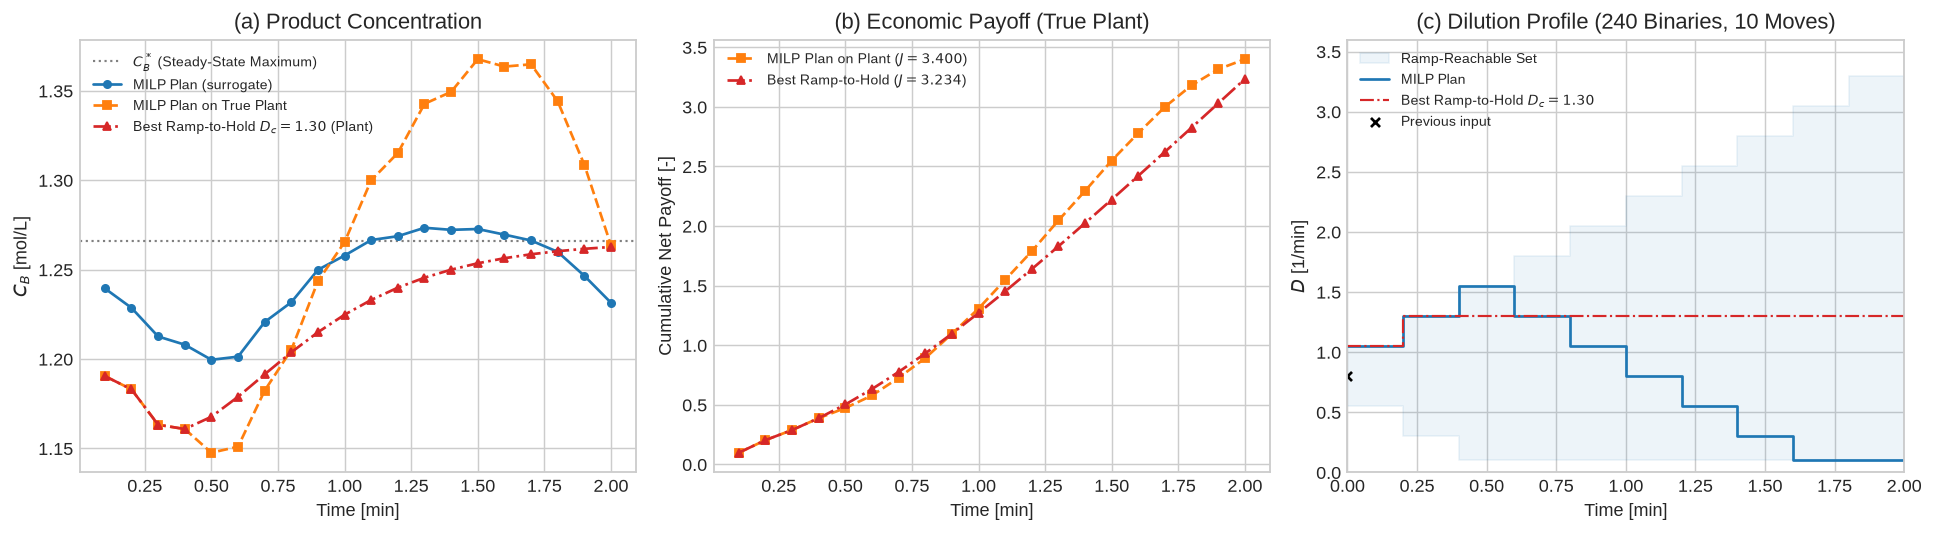

In [ ]:
t_axis = np.arange(1, H_econ + 1) * DT

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) product concentration: plan vs true plant vs best ramp-to-hold baseline
ax[0].axhline(cb_star, ls=":", c="grey", lw=1.2, label="$C_B^*$ (Steady-State Maximum)")
ax[0].plot(t_axis, surrogate_cb, "o-", ms=4, label="MILP Plan (surrogate)")
ax[0].plot(t_axis, y_plant[:, CB], "s--", ms=4, label="MILP Plan on True Plant")
ax[0].plot(t_axis, y_base[:, CB], "^-.", ms=4, c="tab:red",
           label=f"Best Ramp-to-Hold $D_c={d_best:.2f}$ (Plant)")
ax[0].set_xlabel("Time [min]"); ax[0].set_ylabel("$C_B$ [mol/L]")
ax[0].set_title("(a) Product Concentration")
ax[0].legend(fontsize=8, loc="upper left")

# (b) cumulative NET payoff: include the same move cost used in J
move_cost_plant = MOVE_W * np.abs(np.diff(np.r_[u_prev, u_econ[:, 0]]))
move_cost_base = MOVE_W * np.abs(np.diff(np.r_[u_prev, u_base]))
ax[1].plot(t_axis, np.cumsum(DT * rate_plant - move_cost_plant), "s--", ms=4, c="tab:orange",
           label=f"MILP Plan on Plant ($J={J_plant:.3f}$)")
ax[1].plot(t_axis, np.cumsum(DT * rate_base - move_cost_base), "^-.", ms=4, c="tab:red",
           label=f"Best Ramp-to-Hold ($J={J_base:.3f}$)")
ax[1].set_xlabel("Time [min]"); ax[1].set_ylabel("Cumulative Net Payoff [-]")
ax[1].set_title("(b) Economic Payoff (True Plant)")
ax[1].legend(fontsize=8, loc="upper left")

# (c) dilution profile with the ramp-rate envelope
node_t = np.r_[0.0, t_axis]
# Inputs act on [t*DT, (t+1)*DT); extend the final value to the horizon.
env = np.array([ramp_box(t) for t in range(H_econ)] + [ramp_box(H_econ - 1)])
ax[2].fill_between(node_t, env[:, 0], env[:, 1], step="post",
                   color="tab:blue", alpha=0.08, label="Ramp-Reachable Set")
ax[2].step(node_t, np.r_[u_econ[:, 0], u_econ[-1, 0]], where="post", label="MILP Plan")
ax[2].step(node_t, np.r_[u_base, u_base[-1]], where="post", ls="-.", c="tab:red",
           lw=1.2, label=f"Best Ramp-to-Hold $D_c={d_best:.2f}$")
ax[2].set_xlabel("Time [min]"); ax[2].set_ylabel("$D$ [1/min]")
ax[2].scatter([0], [u_prev], marker="x", color="black", s=25, label="Previous input")
ax[2].set_xlim(0, H_econ * DT)
ax[2].set_ylim(0, float(env[:, 1].max()) + 0.3)
ax[2].set_title(f"(c) Dilution Profile ({H_econ * small.n_hidden} Binaries, "
                f"{H_econ // BLOCK} Moves)")
ax[2].legend(fontsize=8, loc="upper left")

plt.tight_layout()
FIG_STEM = ROOT / "images" / "12_vdv_rnn_economic_payoff"
fig.savefig(FIG_STEM.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(FIG_STEM.with_suffix(".png"), dpi=300, bbox_inches="tight")
ARTICLE_STEM = ROOT / "images" / "article" / "vdv_rnn_economic_payoff"
ARTICLE_STEM.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTICLE_STEM.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(ARTICLE_STEM.with_suffix(".png"), dpi=300, bbox_inches="tight")
print("saved:", FIG_STEM.with_suffix(".pdf"), "and", ARTICLE_STEM.with_suffix(".pdf"))
plt.show()

## Summary

* A **physics-informed ReLU-RNN** (data loss + high bound penalty + Van de Vusse ODE
  residual) learns the CSTR dynamics with a compact latent state — the bound penalty
  keeps predictions physical and the residual enforces the known mass balances.
* **Pruning before embedding** shrank the cell (exact dead-unit removal, then
  importance-based trimming to 12 units) with only a modest CB-accuracy cost, which in
  turn shrinks the number of MILP binaries.
* The pruned cell **bound-tightens and unrolls** into a receding-horizon `relu_bigm`
  MILP that reaches `CB*`, and the embedding is **exact** (MILP prediction matches the
  numpy rollout to machine precision).
* The same unrolled model carries a **custom economic objective**: over a 2-min,
  ramp-limited horizon (20 steps, 240 binaries) the MILP plans a dilution ramp that
  maximizes the running payoff (product revenue minus byproduct and feed costs) and
  **beats the best ramp-to-and-hold policy on the true plant**, not just on the
  surrogate. Ramp-aware bound propagation + move blocking turn an hours-long solve
  into a **certified optimum in minutes**.

Everything here is reusable: `RNNTrainer` (physics hooks), `RecurrentCell`
(`rollout`/`encode`/`prune_dead_units`/`prune_least_important`/`recurrent_bounds`/
`solve_mpc`), and the `pwlnet.recurrent` bounds + unroll modules.